
# 07 — Model Inference

## Objective

Load the trained CNN and use it to classify individual
brain images.

Inference workflow:

1. Load the trained model.
2. Read the input image.
3. Apply the same preprocessing used during training.
4. Add a batch dimension.
5. Generate the model's four output scores.
6. Select the class with the highest score.

The model produces classification estimates for
educational use, not validated clinical diagnoses.


In [ ]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.brainscan import (
    preprocess_image,
    CLASS_NAMES
)

model = tf.keras.models.load_model(
    PROJECT_ROOT / "models/experiments/v3_scheduler/best_cnn.keras"
)

print("Model loaded successfully.")


ValueError: File not found: filepath=/home/houssam/Desktop/Briefs/Brief 4/models/v3_scheduler/best_cnn.keras. Please ensure the file is an accessible `.keras` zip file.

In [5]:
def predict_image(image_path):

    image = preprocess_image(image_path)

    # Add batch dimension: (1, 224, 224, 1)
    batch = np.expand_dims(image, axis=0)

    probabilities = model.predict(
        batch,
        verbose=0
    )[0]

    predicted_id = np.argmax(probabilities)

    predicted_class = CLASS_NAMES[predicted_id]

    return predicted_class, probabilities


Actual class: pituitary
Predicted class: pituitary

Model output:
glioma: 0.24%
meningioma: 3.31%
notumor: 0.05%
pituitary: 96.40%


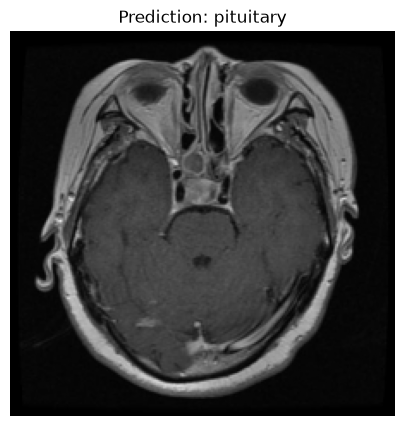

In [6]:
manifest = pd.read_csv(
    PROJECT_ROOT / "data/splits/split_manifest.csv"
)

sample = manifest[
    manifest["split"] == "test"
].iloc[0]

image_path = PROJECT_ROOT / sample["path"]

predicted_class, probabilities = predict_image(
    image_path
)

print("Actual class:", sample["label"])
print("Predicted class:", predicted_class)

print("\nModel output:")
for class_name, score in zip(CLASS_NAMES, probabilities):
    print(f"{class_name}: {score:.2%}")

plt.figure(figsize=(5, 5))

plt.imshow(
    preprocess_image(image_path).squeeze(),
    cmap="gray",
    vmin=0,
    vmax=1
)

plt.title(f"Prediction: {predicted_class}")
plt.axis("off")
plt.show()
